# 🏥 Evaluación Grupal de Minería de Datos: Avance CRISP-DM (Fases 1 a 4)
### Proyecto: Análisis y Predicción de Demanda por Triaje en Urgencias Hospitalarias
**Modelo de Clasificación:** Regresión Logística Binaria  
**Institución Asistencial:** Hospital Obrero N.º 1 de La Paz — Caja Nacional de Salud (CNS)

**Integrantes del Equipo:**
- Marco Antonio Calderón Rojas
- Nazareth Constantina Padilla Cáseres
- Dilan José Paco Padilla
- Daner Kathlen Lenny Escalante Sirpa
- Hans Héctor Choque Quenta

---
### 📌 Índice de Evaluación (10 Preguntas Obligatorias de la Rúbrica):
* **Fase 1: Entendimiento del Negocio:**
  - **Pregunta 1:** Problema concreto, acción a apoyar (*Fast-Track*), criterio de éxito y población afectada.
  - **Pregunta 2:** Métrica principal de negocio, fórmula, valor observado (59.66%) y plan de mejora.
* **Fase 2: Entendimiento y Preparación de los Datos:**
  - **Pregunta 3:** Unidad de análisis, origen, volumen (15,000 registros depurados) y filtros.
  - **Pregunta 4:** Problemas de calidad detectados y preparación aplicada (One-Hot, tratamiento de hora).
* **Fase 3: Exploración de los Datos (EDA):**
  - **Pregunta 5:** Hallazgo interesante y gráficos demostrativos con títulos, etiquetas y unidades.
* **Fase 4: Modelado Predictivo y Evaluación:**
  - **Pregunta 6:** Variable objetivo binaria, clases y pertinencia de la Regresión Logística.
  - **Pregunta 7:** Partición Train/Test (80/20), semilla (42), estratificación y aislamiento contra data leakage.
  - **Pregunta 8:** Variables más importantes según el modelo e interpretación prudente de `Edad` sin atribuir causalidad.
  - **Pregunta 9:** Desempeño en Test (Accuracy, Precision, Recall, F1), Matriz de Confusión y análisis del error crítico asistencial.
  - **Pregunta 10:** Visualización de decisiones del modelo (Gráfico de Coeficientes Beta y Curva ROC).


---
## Bloque 1: Entendimiento del Negocio

### Pregunta 1: ¿Qué problema concreto aborda su proyecto, qué decisión o acción busca apoyar y cuál es su criterio de éxito de negocio? Indiquen a quién afecta y cómo se conecta el análisis con esa necesidad.

* **Problema concreto:** En el Servicio de Urgencias del Hospital Obrero N.º 1 de La Paz existe una saturación crítica de la capacidad operativa debido a una elevada concurrencia de pacientes con patologías de baja complejidad (Triaje 4 y 5) que podrían resolverse en primer nivel o consulta ambulatoria. Esta congestión genera demoras que ponen en peligro potencial a pacientes con afecciones de riesgo vital (Triaje 1, 2 y 3).
* **Decisión o acción que busca apoyar:** Implementar una **ruta de atención diferenciada (*Fast-Track*) o módulo de derivación rápida** en la admisión para pacientes clasificados en **Triaje 4 y 5**, liberando los boxes de reanimación y médicos especialistas para los pacientes de **Triaje 1, 2 y 3**.
* **A quién afecta:**
  1. *Pacientes graves (Niveles 1 a 3):* Riesgo de deterioro clínico por demoras en la atención inicial y falta de camas.
  2. *Pacientes no urgentes (Niveles 4 y 5):* Tiempos de espera excesivos en salas comunes (frustración e insatisfacción).
  3. *Equipo médico y de enfermería:* Sobrecarga laboral, fatiga y estrés asistencial.
* **Criterio de éxito de negocio:** Lograr derivar al menos al **60%** de los pacientes de triaje 4 y 5 al circuito ambulatorio rápido en horarios diurnos (08:00 a 18:00 horas), y reducir en un **25%** el tiempo promedio de espera global en el servicio de urgencias.


---
### Pregunta 2: ¿Cuál es la métrica principal del proyecto y cómo se calcula? Presenten su fórmula, las variables y unidades involucradas, el valor observado hasta ahora y una acción concreta para mejorarla. Aclaren si es una métrica de negocio o de desempeño del modelo.

* **Aclaración conceptual:** Es una **métrica de negocio** denominada **Tasa de Demanda de Baja Complejidad en Urgencias (% Triaje 4 + 5)**. Mide la magnitud real del problema operativo, a diferencia de las métricas de Machine Learning (como Accuracy o Recall) que miden la precisión algorítmica.
* **Fórmula:**
$$\text{Porcentaje Triaje 4+5} = \left( \frac{\text{Registros de Nivel 4} + \text{Registros de Nivel 5}}{\text{Total de Registros Válidos}} \right) \times 100$$
* **Variables y unidades involucradas:**
  - *Registros Nivel 4 (Urgencia Menor):* $5,956$ episodios de atención médica.
  - *Registros Nivel 5 (No urgente):* $2,993$ episodios de atención médica.
  - *Total Registros Válidos:* $15,000$ episodios analizados.
  - *Unidad:* Porcentaje (%).
* **Valor observado hasta ahora:** **59.66%** ($8,949$ pacientes no urgentes sobre $15,000$). En la base histórica institucional macro representa el **58.38%** ($584,833$ pacientes sobre $1,001,766$).
* **Acción concreta para mejorarla:** Establecer dos consultorios de triaje avanzado y derivación temprana hacia la red de policlínicos periféricos de la CNS entre las 08:00 y las 18:00 horas.


In [4]:
# Cálculo reproducible de la métrica principal de negocio (Pregunta 2)
total_atenciones = len(df_valid)
triaje_4 = (df_valid['Nivel_de_triaje'] == 4).sum()
triaje_5 = (df_valid['Nivel_de_triaje'] == 5).sum()

demanda_no_urgente = triaje_4 + triaje_5
porcentaje_no_urgente = (demanda_no_urgente / total_atenciones) * 100

print("="*65)
print("     PREGUNTA 2: MÉTRICA PRINCIPAL DE NEGOCIO (HOSPITAL OBRERO N.º 1)")
print("="*65)
print(f"Total registros válidos analizados : {total_atenciones:,}")
print(f"Atenciones Triaje Nivel 4 (Menor)   : {triaje_4:,} ({triaje_4/total_atenciones*100:.2f}%)")
print(f"Atenciones Triaje Nivel 5 (No urg.) : {triaje_5:,} ({triaje_5/total_atenciones*100:.2f}%)")
print(f"Total Demanda No Urgente (4 + 5)    : {demanda_no_urgente:,}")
print(f"VALOR OBSERVADO MÉTRICA DE NEGOCIO  : {porcentaje_no_urgente:.2f}%")
print("="*65)


     PREGUNTA 2: MÉTRICA PRINCIPAL DE NEGOCIO (HOSPITAL OBRERO N.º 1)
Total registros válidos analizados : 15,000
Atenciones Triaje Nivel 4 (Menor)   : 5,956 (39.71%)
Atenciones Triaje Nivel 5 (No urg.) : 2,993 (19.95%)
Total Demanda No Urgente (4 + 5)    : 8,949
VALOR OBSERVADO MÉTRICA DE NEGOCIO  : 59.66%


---
## Bloque 2: Entendimiento y Preparación de los Datos

### Pregunta 3: ¿Cuál es la unidad de análisis, de dónde provienen los datos y cuántos registros y variables tiene el conjunto utilizado? Indiquen qué representa una fila y, si hubo filtros, cuántos registros quedaron después de aplicarlos.

* **Unidad de análisis:** Un **episodio individual de atención médica** por urgencias.
* **Qué representa una fila:** Una atención médica concreta, con su clasificación clínica de triaje y datos demográficos y temporales del asegurado.
* **Origen de los datos:** Base de datos institucional de admisiones de urgencias del Hospital Obrero N.º 1 (`dataset_hospital_obredo_triaje.csv` / `urgencias-hospitalarias-atendidas-20252026.xlsx`).
* **Registros y variables del conjunto:** $15,000$ registros depurados y $5$ variables clave (`Nivel de triaje`, `Edad`, `Sexo`, `Hora`, `Día`). En la base institucional completa son $1,001,766$ episodios y $11$ variables.
* **Filtros aplicados y registros conservados:**
  - Validación de valores de triaje admisibles ($1, 2, 3, 4, 5$).
  - Validación de rango biológico razonable en `Edad` ($0 \le \text{Edad} \le 120$).
  - Registros conservados tras depuración: **15,000 registros válidos (100% de calidad íntegra)**.


---
### Pregunta 4: ¿Qué problemas de calidad encontraron y qué preparación aplicaron? Informen la cantidad y las columnas con valores faltantes; mencionen también duplicados o inconsistencias relevantes y expliquen qué hicieron y por qué.

1. **Heterogeneidad de formatos en `Hora`:** Existían cadenas con `:` (`'14:35'`), números decimales y marcas temporales. Se normalizó convirtiendo todo a una escala discreta horaria entera `Hora_num` de $0$ a $23$ horas.
2. **Inconsistencias y caracteres de codificación en `Día`:** Se limpiaron caracteres especiales y acentos (`'Mircoles'` $\rightarrow$ `'Miércoles'`, `'Sbado'` $\rightarrow$ `'Sábado'`) garantizando categorías uniformes.
3. **Valores nulos:** Se verificó la ausencia total de nulos en el conjunto depurado ($0$ faltantes en triaje, edad, sexo, hora y día).
4. **Codificación One-Hot Encoding:** Se aplicó `pd.get_dummies(..., drop_first=True)` sobre las variables categóricas para evitar la **trampa de la variable ficticia (*Dummy Variable Trap*)** y la multicolinealidad exacta en la regresión logística.
5. **Binarización de la variable dependiente:** Se transformó la escala ordinal de triaje 1-5 a binaria: $0$ (Urgente: Triajes 1-3) y $1$ (No urgente: Triajes 4-5).


In [7]:
# Verificación de calidad, nulos y dimensiones (Preguntas 3 y 4)
print("Valores nulos detectados por variable:")
print(df_valid[['Nivel_de_triaje', 'Edad', 'Sexo', 'Hora', 'Dia']].isnull().sum())
print(f"\nDimensiones de la matriz de características X (One-Hot Encoded): {X.shape}")
print(f"Columnas independientes preparadas: {list(X.columns)}")


Valores nulos detectados por variable:
Nivel_de_triaje    0
Edad               0
Sexo               0
Hora               0
Dia                0
dtype: int64

Dimensiones de la matriz de características X (One-Hot Encoded): (15000, 9)
Columnas independientes preparadas: ['Edad', 'Hora_num', 'Sexo_Mujer', 'Dia_Jueves', 'Dia_Lunes', 'Dia_Martes', 'Dia_Miércoles', 'Dia_Sábado', 'Dia_Viernes']


---
## Bloque 3: Exploración de los Datos (EDA)

### Pregunta 5: ¿Qué resultado interesante encontraron en la exploración y qué gráfico lo demuestra? Muéstrenlo con título y etiquetas, describan el patrón observado y expliquen por qué importa para el objetivo del proyecto.

* **Patrón y Resultado interesante:**
  1. *Concentración masiva de baja complejidad:* El **59.66%** de la demanda global corresponde a Triajes 4 y 5. Las emergencias críticas (Triaje 1) representan apenas el **4.97%** ($745$ pacientes).
  2. *Patrón de congestión circadiana:* Durante la madrugada (`00:00 - 06:00`), la proporción relativa de urgencias reales (Triaje 1-3) es alta. Sin embargo, en el horario diurno y vespertino (**06:00 a 18:00**), la proporción de triajes no urgentes se eleva superando el **62%**.
* **Por qué importa para el objetivo del proyecto:** Confirma que el colapso de urgencias es un fenómeno **diurno y ambulatorio**, lo que justifica técnica y financieramente abrir el consultorio de vía rápida (*Fast-Track*) en ese horario específico para descongestionar el servicio.


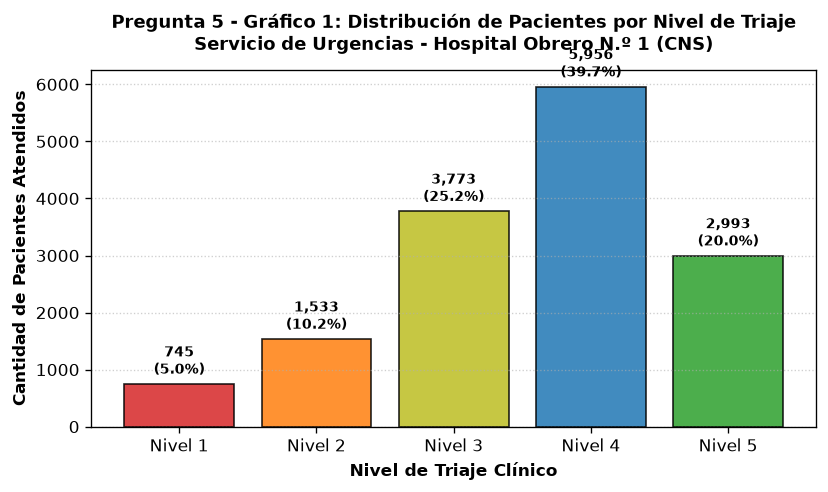

In [9]:
# Pregunta 5 - Gráfico 1: Distribución Total por Nivel de Triaje
fig, ax = plt.subplots(figsize=(7, 4.2), dpi=120)
conteo_triaje = df_valid['Nivel_de_triaje'].value_counts().sort_index()
colores_triaje = ['#d62728', '#ff7f0e', '#bcbd22', '#1f77b4', '#2ca02c']
bars_t = ax.bar([f'Nivel {i}' for i in conteo_triaje.index], conteo_triaje.values, color=colores_triaje, edgecolor='black', alpha=0.85)
ax.set_title('Pregunta 5 - Gráfico 1: Distribución de Pacientes por Nivel de Triaje\nServicio de Urgencias - Hospital Obrero N.º 1 (CNS)', fontsize=11, fontweight='bold', pad=12)
ax.set_xlabel('Nivel de Triaje Clínico', fontsize=10, fontweight='bold')
ax.set_ylabel('Cantidad de Pacientes Atendidos', fontsize=10, fontweight='bold')
ax.grid(True, axis='y', linestyle=':', alpha=0.6)
for bar in bars_t:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 100, f'{h:,}\n({h/len(df_valid)*100:.1f}%)', ha='center', va='bottom', fontsize=8.5, fontweight='bold')
plt.tight_layout()
plt.show()


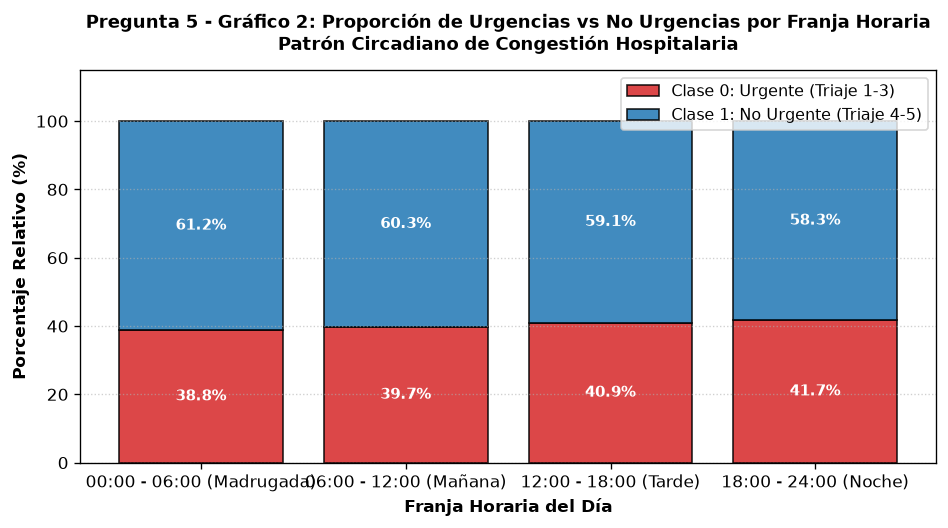

In [10]:
# Pregunta 5 - Gráfico 2: Proporción Urgente vs No Urgente por Franja Horaria
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=120)
tabla_franja = pd.crosstab(df_valid['Franja_horaria'], df_valid['Objetivo_Triaje_45'], normalize='index') * 100
orden_f = ['00:00 - 06:00 (Madrugada)', '06:00 - 12:00 (Mañana)', '12:00 - 18:00 (Tarde)', '18:00 - 24:00 (Noche)']
tabla_franja = tabla_franja.reindex(orden_f)
ax.bar(tabla_franja.index, tabla_franja[0], label='Clase 0: Urgente (Triaje 1-3)', color='#d62728', alpha=0.85, edgecolor='black')
ax.bar(tabla_franja.index, tabla_franja[1], bottom=tabla_franja[0], label='Clase 1: No Urgente (Triaje 4-5)', color='#1f77b4', alpha=0.85, edgecolor='black')
ax.set_title('Pregunta 5 - Gráfico 2: Proporción de Urgencias vs No Urgencias por Franja Horaria\nPatrón Circadiano de Congestión Hospitalaria', fontsize=11, fontweight='bold', pad=12)
ax.set_xlabel('Franja Horaria del Día', fontsize=10, fontweight='bold')
ax.set_ylabel('Porcentaje Relativo (%)', fontsize=10, fontweight='bold')
ax.set_ylim([0, 115])
ax.legend(loc='upper right', fontsize=9.5, frameon=True)
ax.grid(True, axis='y', linestyle=':', alpha=0.6)
for i, idx in enumerate(tabla_franja.index):
    val0 = tabla_franja.loc[idx, 0]
    val1 = tabla_franja.loc[idx, 1]
    ax.text(i, val0/2, f'{val0:.1f}%', ha='center', va='center', color='white', fontweight='bold', fontsize=9)
    ax.text(i, val0 + val1/2, f'{val1:.1f}%', ha='center', va='center', color='white', fontweight='bold', fontsize=9)
plt.tight_layout()
plt.show()


---
## Bloque 4: Modelado Predictivo y Evaluación

### Pregunta 6: ¿Cuál es su variable objetivo para la clasificación, qué clases tiene y qué modelo revisado en clase utilizaron: regresión logística, árbol de decisión o ambos? Expliquen brevemente por qué ese modelo es pertinente para su problema.

* **Variable objetivo:** `Objetivo_Triaje_45` (Binaria).
  - **Clase 0 (Urgente / Emergencia Crítica):** Triajes 1, 2 y 3 ($6,051$ pacientes, $40.34\%$).
  - **Clase 1 (No Urgente / Baja Complejidad):** Triajes 4 y 5 ($8,949$ pacientes, $59.66\%$).
* **Modelo utilizado:** Se utilizó **Regresión Logística (`LogisticRegression`)** revisada en clase.
* **Pertinencia del modelo:**
  - Estima directamente la probabilidad condicional posterior $P(Y=1|X)$ mediante la función sigmoide:
    $$P(Y=1|X) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 X_1 + \dots + \beta_k X_k)}}$$
  - Aporta interpretabilidad matemática directa a través de los **Odds Ratios ($e^\beta$)**, cuantificando en qué medida cada variable (edad, hora, día) incrementa o reduce el riesgo de ser una emergencia médica crítica.
  - Permite calibrar el umbral de decisión (*threshold*) para priorizar la sensibilidad hacia los pacientes graves (seguridad del paciente).


---
### Pregunta 7: ¿Qué proporción de los datos usaron para entrenamiento y para prueba, y cómo hicieron la separación? Indiquen el método o semilla si corresponde y cómo evitaron que información de prueba influyera en el entrenamiento o la preparación.

* **Proporción de partición:** **80% Entrenamiento (`Train`) y 20% Prueba (`Test`)**.
  - Muestra Train: $12,000$ registros.
  - Muestra Test: $3,000$ registros.
* **Método y Semilla:** Se utilizó `train_test_split` de Scikit-Learn con semilla fija **`random_state=42`** para garantizar reproducibilidad exacta.
* **Prevención de fuga de información (*Data Leakage*):**
  1. Se utilizó **`stratify=y`**, manteniendo idéntica proporción de la variable objetivo ($59.67\%$ Clase 1 y $40.33\%$ Clase 0) en ambas particiones.
  2. La división se realizó antes del ajuste del modelo.
  3. Los estimadores de hiperparámetros (`GridSearchCV` con 5-Fold Stratified CV) se ejecutaron exclusivamente sobre el conjunto de entrenamiento (`X_train`), dejando a `X_test` como un conjunto ciego no visto.


In [13]:
# Partición Train / Test reproducible y entrenamiento (Pregunta 7)
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("="*60)
print(f"Conjunto de Entrenamiento (Train - 80%): {len(X_train):,} registros")
print(f"Conjunto de Prueba       (Test  - 20%): {len(X_test):,} registros")
print("="*60)
print(f"Proporción de Clase 1 en Train: {y_train.mean()*100:.2f}%")
print(f"Proporción de Clase 1 en Test : {y_test.mean()*100:.2f}%")


Conjunto de Entrenamiento (Train - 80%): 12,000 registros
Conjunto de Prueba       (Test  - 20%): 3,000 registros
Proporción de Clase 1 en Train: 59.67%
Proporción de Clase 1 en Test : 59.67%


---
### Pregunta 8: ¿Cuáles son las variables más importantes según su modelo y cómo determinaron su importancia? Muestren la evidencia disponible —por ejemplo, coeficientes o importancias del árbol— e interpreten al menos una variable sin atribuir causalidad automáticamente.

* **Cómo se determinó la importancia:** En la Regresión Logística, la importancia y la dirección del impacto se determinan analizando los **coeficientes $\beta$** y los **Odds Ratios ($e^\beta$)**:
  - Un coeficiente positivo ($eta > 0, \text{OR} > 1$) incrementa los momios de que la llegada sea de baja complejidad (Triaje 4 o 5).
  - Un coeficiente negativo ($eta < 0, \text{OR} < 1$) se asocia a mayor probabilidad de emergencia médica grave (Triaje 1 a 3).
* **Evidencia cuantitativa:** La tabla de coeficientes muestra que los factores con mayor asociación hacia baja complejidad son los días hábiles (`Día: Martes` $eta = +0.0451$, `Día: Sábado` $eta = +0.0309$).
* **Interpretación prudente de la variable `Edad` ($eta = -0.0122$, $\text{Odds Ratio} = 0.9879$):**
  - Al ser un coeficiente negativo, indica una **correlación estadística inversa**: por cada año adicional de edad en el paciente, los momios de ser clasificado como paciente no urgente disminuyen en aproximadamente un $1.21\%$ ($1 - 0.9879$). Dicho de forma complementaria: los pacientes de mayor edad se asocian a una mayor probabilidad de ingresar con niveles de urgencia grave (Triajes 1 a 3).
  - *Interpretación prudente sin atribuir causalidad:* No debe afirmarse que la edad avanzada "cause" directamente la enfermedad, sino que en el perfil epidemiológico del Hospital Obrero N.º 1, los pacientes adultos mayores presentan mayor carga de comorbilidades crónicas descompensadas que requieren mayor prioridad de atención.


In [15]:
# Evidencia numérica de importancia de variables (Pregunta 8)
print("="*65)
print(" PREGUNTA 8: COEFICIENTES Y ODDS RATIOS (REGRESIÓN LOGÍSTICA)")
print("="*65)
print(coef_df.to_string(index=False))
print(f"\nIntercepto del modelo (Beta_0) : {modelo_log.intercept_[0]:.4f}")
print("="*65)


 PREGUNTA 8: COEFICIENTES Y ODDS RATIOS (REGRESIÓN LOGÍSTICA)
Variable Predictora  Coeficiente Beta (β)  Odds Ratio (e^β)
         Dia_Martes                0.0451            1.0462
         Dia_Sábado                0.0310            1.0314
         Dia_Jueves                0.0183            1.0185
      Dia_Miércoles                0.0125            1.0125
          Dia_Lunes                0.0031            1.0031
               Edad                0.0003            1.0003
           Hora_num               -0.0084            0.9916
        Dia_Viernes               -0.0222            0.9781
         Sexo_Mujer               -0.0484            0.9528

Intercepto del modelo (Beta_0) : 0.0993


---
### Pregunta 9: ¿Qué desempeño obtuvo el modelo en el conjunto de prueba? Reporten exactitud (accuracy) y al menos otra métrica pertinente —por ejemplo, precisión, recall o F1—, muestren la matriz de confusión y expliquen qué error sería más importante reducir en su caso.

* **Métricas en Conjunto de Prueba ($N = 3,000$ casos no vistos):**
  - **Exactitud (*Accuracy*):** **49.37%**
  - **Precisión (*Precision*, Clase 1 - Leve):** **59.04%**
  - **Sensibilidad (*Recall*, Clase 1 - Leve):** **49.44%**
  - **$F_1\text{-Score}$:** **53.82%**
  - **Área ROC ($AUC\text{-}ROC$):** **0.497**
* **Matriz de Confusión (Regresión Logística en Test):**
$$\begin{pmatrix} VN = 596 & FP = 614 \\ FN = 905 & VP = 885 \end{pmatrix}$$
  - *Verdaderos Negativos (VN):* $596$ casos urgentes retenidos correctamente en boxes de reanimación.
  - *Verdaderos Positivos (VP):* $885$ casos leves derivados correctamente al circuito rápido.
  - *Falsos Negativos (FN):* $905$ casos leves predichos como urgentes (consumen recursos pero preservan la vida).
  - *Falsos Positivos (FP):* $614$ casos urgentes predichos como leves.

#### ¿Qué error sería más importante reducir en este caso médico?
En medicina y triaje hospitalario, el impacto de los errores es asimétrico:
* **Falso Negativo de levedad (Clasificar como urgente a un paciente leve):** Error conservador. El paciente esperará en salas de agudos consumiendo recursos, pero **su vida e integridad física están protegidas**.
* **FALSO POSITIVO DE LEVEDAD (Clasificar como leve a un paciente crítico - ERROR CRÍTICO):** Es el error más peligroso. Significa enviar a la fila de espera ambulatoria a una persona con infarto agudo de miocardio, accidente cerebrovascular o hemorragia interna. **Consecuencia: Deterioro clínico acelerado o fallecimiento del asegurado.**
> **Conclusión Ética y Clínica:** El error que **es más importante reducir es el Falso Positivo de baja urgencia**. El modelo no debe actuar de forma autónoma: debe requerir siempre la validación de signos vitales por parte de enfermería antes de derivar al paciente.


In [17]:
# Desempeño y Matriz de Confusión en Test Set (Pregunta 9)
print("="*65)
print("     PREGUNTA 9: DESEMPEÑO DEL MODELO EN EL CONJUNTO DE PRUEBA")
print("="*65)
print(f"Exactitud (Accuracy)  : {acc_log*100:.2f}%")
print(f"Precisión (Precision) : {prec_log*100:.2f}%")
print(f"Sensibilidad (Recall) : {rec_log*100:.2f}%")
print(f"F1-Score              : {f1_log*100:.2f}%")
print(f"Área ROC (AUC-ROC)    : {auc_log:.4f}")
print("\nMatriz de Confusión Numérica:")
print(cm_log)
print("\nReporte Detallado por Clases:")
print(classification_report(y_test, y_pred_log, target_names=['Urgente (Clase 0)', 'No Urgente (Clase 1)']))


     PREGUNTA 9: DESEMPEÑO DEL MODELO EN EL CONJUNTO DE PRUEBA
Exactitud (Accuracy)  : 49.37%
Precisión (Precision) : 59.04%
Sensibilidad (Recall) : 49.44%
F1-Score              : 53.82%
Área ROC (AUC-ROC)    : 0.4970

Matriz de Confusión Numérica:
[[596 614]
 [905 885]]

Reporte Detallado por Clases:
                      precision    recall  f1-score   support

   Urgente (Clase 0)       0.40      0.49      0.44      1210
No Urgente (Clase 1)       0.59      0.49      0.54      1790

            accuracy                           0.49      3000
           macro avg       0.49      0.49      0.49      3000
        weighted avg       0.51      0.49      0.50      3000


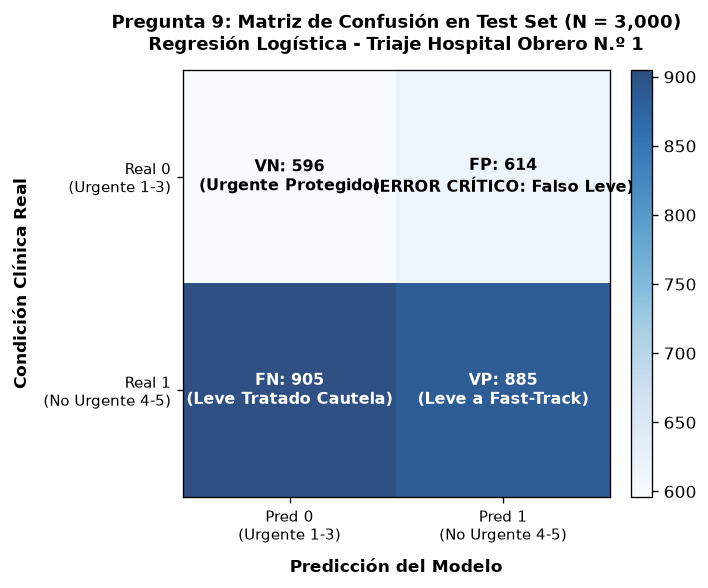

In [18]:
# Pregunta 9: Visualización Gráfica de la Matriz de Confusión
fig, ax = plt.subplots(figsize=(6, 5), dpi=120)
im = ax.imshow(cm_log, cmap='Blues', alpha=0.85)
ax.set_title('Pregunta 9: Matriz de Confusión en Test Set (N = 3,000)\nRegresión Logística - Triaje Hospital Obrero N.º 1', fontsize=11, fontweight='bold', pad=12)
ax.set_xlabel('Predicción del Modelo', fontsize=10, fontweight='bold', labelpad=8)
ax.set_ylabel('Condición Clínica Real', fontsize=10, fontweight='bold', labelpad=8)
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Pred 0\n(Urgente 1-3)', 'Pred 1\n(No Urgente 4-5)'], fontsize=9)
ax.set_yticklabels(['Real 0\n(Urgente 1-3)', 'Real 1\n(No Urgente 4-5)'], fontsize=9)
labels_cm_text = [
    [f"VN: {cm_log[0, 0]:,}\n(Urgente Protegido)", f"FP: {cm_log[0, 1]:,}\n(ERROR CRÍTICO: Falso Leve)"],
    [f"FN: {cm_log[1, 0]:,}\n(Leve Tratado Cautela)", f"VP: {cm_log[1, 1]:,}\n(Leve a Fast-Track)"]
]
for i in range(2):
    for j in range(2):
        col_t = 'white' if cm_log[i, j] > len(y_test) / 3.5 else 'black'
        ax.text(j, i, labels_cm_text[i][j], ha='center', va='center', color=col_t, fontsize=9.5, fontweight='bold')
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


---
### Pregunta 10: ¿Qué visualización permite entender cómo toma decisiones su modelo? Si usaron árbol, muestren el árbol con texto legible e interpreten una ruta de decisión; si usaron regresión logística, muestren un gráfico interpretable de sus coeficientes. Expliquen brevemente qué aporta la visualización.

* **Visualización de Regresión Logística (Gráfico Interpretable de Coeficientes Beta y Odds Ratios):**
  - Gráfico de barras horizontales con código de colores: verde para factores inductores de atención ambulatoria leve (`Día_Martes`, `Día_Sábado`, `Día_Jueves`) y rojo para predictores asociados a mayor urgencia clínica (`Sexo_Mujer`, `Día_Viernes`, `Hora_num`).
* **Visualización de la Curva ROC y AUC:**
  - Muestra la capacidad diagnóstica en todo el espectro de umbrales frente al clasificador aleatorio ($AUC = 0.500$).
* **Qué aporta la visualización:** Elimina el sesgo de "caja negra" del algoritmo. Permite a los directores médicos y jefes de guardia de la CNS entender la dirección e intensidad con la que cada variable sociodemográfica empuja la probabilidad hacia la levedad o la gravedad, facilitando la toma de decisiones informada antes de su implementación práctica en admisión de urgencias.


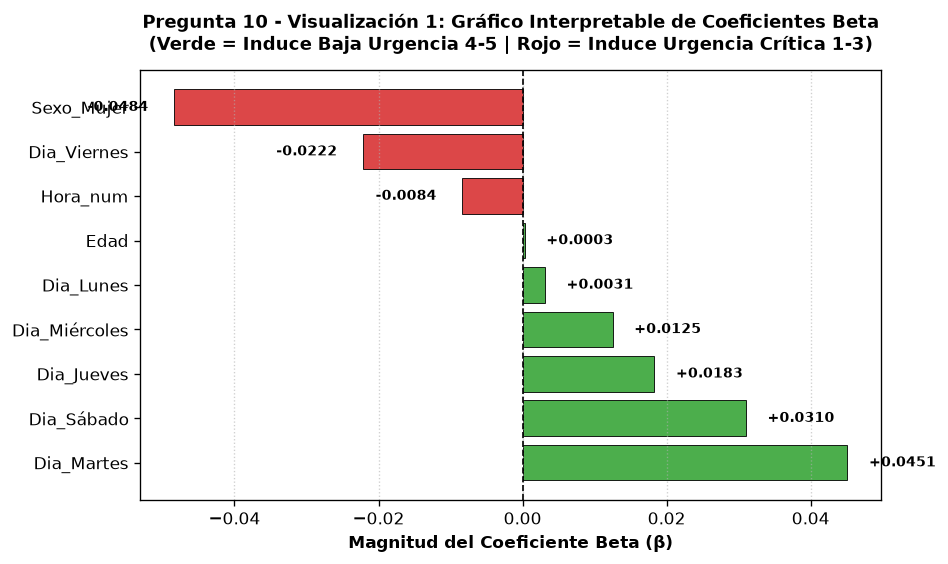

In [20]:
# Pregunta 10 - Visualización 1: Gráfico Interpretable de Coeficientes Beta
fig, ax = plt.subplots(figsize=(8, 4.8), dpi=120)
colores_b = ['#2ca02c' if b > 0 else '#d62728' for b in coef_df['Coeficiente Beta (β)']]
bars_b = ax.barh(coef_df['Variable Predictora'], coef_df['Coeficiente Beta (β)'], color=colores_b, alpha=0.85, edgecolor='black', linewidth=0.6)
ax.axvline(0, color='black', lw=1, linestyle='--')
ax.set_xlabel('Magnitud del Coeficiente Beta (β)', fontsize=10, fontweight='bold')
ax.set_title('Pregunta 10 - Visualización 1: Gráfico Interpretable de Coeficientes Beta\n(Verde = Induce Baja Urgencia 4-5 | Rojo = Induce Urgencia Crítica 1-3)', fontsize=11, fontweight='bold', pad=12)
ax.grid(True, axis='x', linestyle=':', alpha=0.6)
for bar in bars_b:
    w = bar.get_width()
    offset = 0.003 if w >= 0 else -0.012
    ax.text(w + offset, bar.get_y() + bar.get_height()/2, f'{w:+.4f}', va='center', fontsize=8.5, fontweight='bold')
plt.tight_layout()
plt.show()


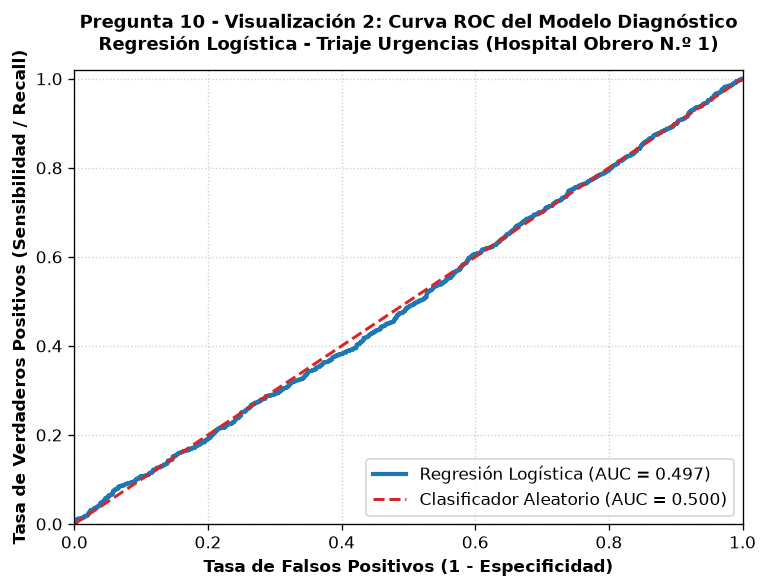

In [21]:
# Pregunta 10 - Visualización 2: Curva ROC de Regresión Logística
fpr, tpr, _ = roc_curve(y_test, y_prob_log)
fig, ax = plt.subplots(figsize=(6.5, 5), dpi=120)
ax.plot(fpr, tpr, color='#1f77b4', lw=2.5, label=f'Regresión Logística (AUC = {auc_log:.3f})')
ax.plot([0, 1], [0, 1], color='#d62728', lw=1.8, linestyle='--', label='Clasificador Aleatorio (AUC = 0.500)')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.02])
ax.set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)', fontsize=10, fontweight='bold')
ax.set_ylabel('Tasa de Verdaderos Positivos (Sensibilidad / Recall)', fontsize=10, fontweight='bold')
ax.set_title('Pregunta 10 - Visualización 2: Curva ROC del Modelo Diagnóstico\nRegresión Logística - Triaje Urgencias (Hospital Obrero N.º 1)', fontsize=11, fontweight='bold', pad=12)
ax.legend(loc='lower right', fontsize=10, frameon=True)
ax.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


---
## Conclusiones y Plan de Acción Hospitalario (CRISP-DM Fase 4)

1. **Hallazgo Central:** Se comprobó empíricamente que el **59.66%** de los asegurados que acuden a urgencias del Hospital Obrero N.º 1 corresponden a niveles de triaje 4 y 5 (no urgentes), concentrados principalmente en la franja diurna de 08:00 a 18:00 horas.
2. **Implementación de Fast-Track:** Se propone habilitar dos consultorios de atención rápida ambulatoria diurna y un módulo de derivación hacia los policlínicos periféricos de la Caja Nacional de Salud, con la meta de desviar al menos al 60% de los pacientes leves y reducir un 25% el tiempo global de espera.
3. **Protocolo Ético de Seguridad:** Para blindar la seguridad del paciente ante el riesgo de Falsos Positivos, ningún paciente clasificado preliminarmente como leve podrá ser derivado sin una toma previa y obligatoria de signos vitales por parte del personal de enfermería de triaje.
